Notebook para analizar el comportamiento del frijol, haba y maíz en todos los municipios de México

In [1]:
# [CELDA 1: Importaciones y Carga]
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética para las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Cargar el dataset
df_precios = pd.read_csv('precios_historicos_sniim_continuo.csv')

# Vistazo inicial
display(df_precios.head())
display(df_precios.info())

,Fecha,Origen,Precio Mín,Precio Max,Precio Frec,Producto_Buscado,Año,Mes,Semana
0,07/01/2015,México,4.8,5.0,4.8,Maíz blanco,2015,1,1
1,14/01/2015,México,4.8,5.0,4.8,Maíz blanco,2015,1,2
2,21/01/2015,México,4.8,5.0,4.8,Maíz blanco,2015,1,3
3,28/01/2015,México,4.8,5.0,4.8,Maíz blanco,2015,1,4
4,04/02/2015,México,4.8,5.0,4.8,Maíz blanco,2015,2,1


<class 'pandas.DataFrame'>
RangeIndex: 2577 entries, 0 to 2576
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Fecha             2031 non-null   str    
 1   Origen            2031 non-null   str    
 2   Precio Mín        2031 non-null   float64
 3   Precio Max        2031 non-null   float64
 4   Precio Frec       2031 non-null   float64
 5   Producto_Buscado  2577 non-null   str    
 6   Año               2577 non-null   int64  
 7   Mes               2577 non-null   int64  
 8   Semana            2577 non-null   int64  
dtypes: float64(3), int64(3), str(3)
memory usage: 181.3 KB


None

In [2]:
# [CELDA 2: Limpieza y formato de tipos de datos]

# 1. Convertir la columna 'Fecha' a datetime (especificando el formato día/mes/año)
df_precios['Fecha'] = pd.to_datetime(df_precios['Fecha'], format='%d/%m/%Y')

# 2. Asegurarnos de que los precios son numéricos (por si quedó algún carácter oculto)
columnas_precio = ['Precio Mín', 'Precio Max', 'Precio Frec']
for col in columnas_precio:
    df_precios[col] = pd.to_numeric(df_precios[col], errors='coerce')

# 3. Ordenar cronológicamente el dataset
df_precios = df_precios.sort_values(by=['Producto_Buscado', 'Fecha']).reset_index(drop=True)

print("Valores nulos por columna:")
print(df_precios.isnull().sum())

Valores nulos por columna:
Fecha               546
Origen              546
Precio Mín          546
Precio Max          546
Precio Frec         546
Producto_Buscado      0
Año                   0
Mes                   0
Semana                0
dtype: int64


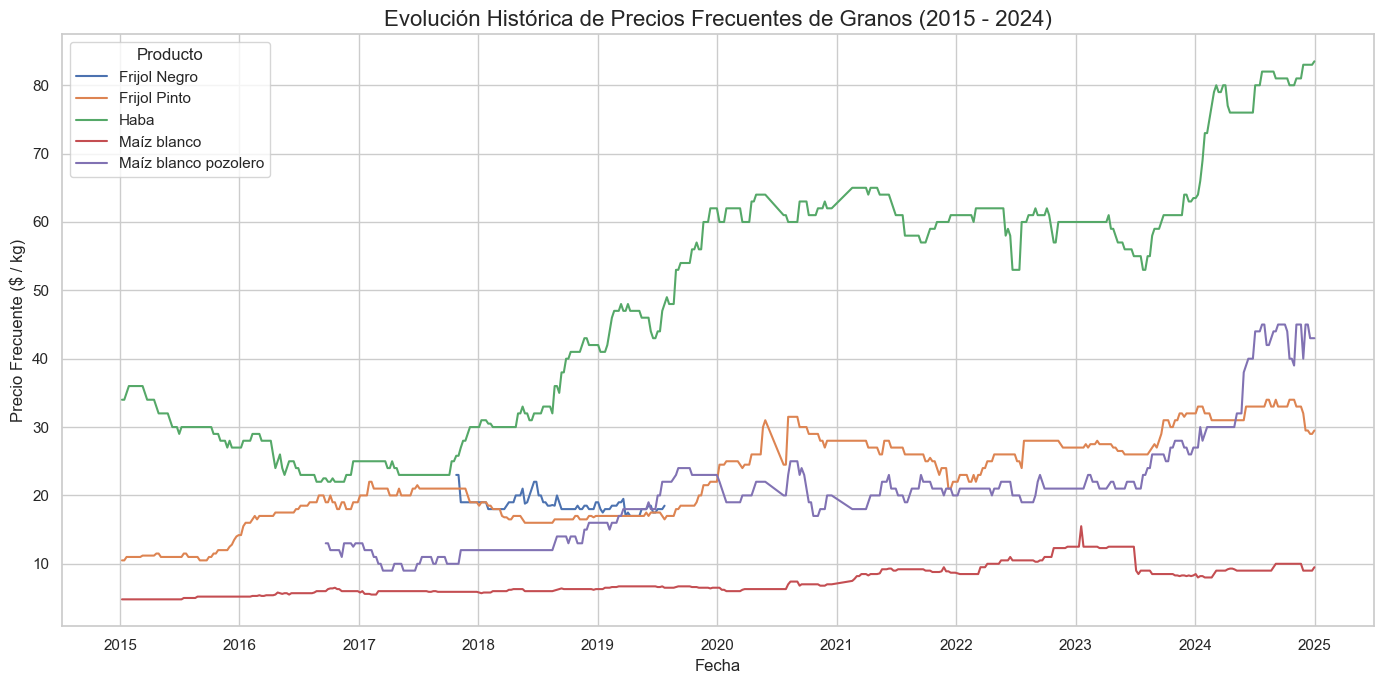

In [3]:
# [CELDA 3: Gráfica histórica de precios por semilla]

plt.figure(figsize=(14, 7))

# Graficamos una línea de tiempo por cada producto
sns.lineplot(data=df_precios, x='Fecha', y='Precio Frec', hue='Producto_Buscado', linewidth=1.5)

plt.title('Evolución Histórica de Precios Frecuentes de Granos (2015 - 2024)', fontsize=16)
plt.ylabel('Precio Frecuente ($ / kg)', fontsize=12)
plt.xlabel('Fecha', fontsize=12)
plt.legend(title='Producto')
plt.tight_layout()
plt.show()

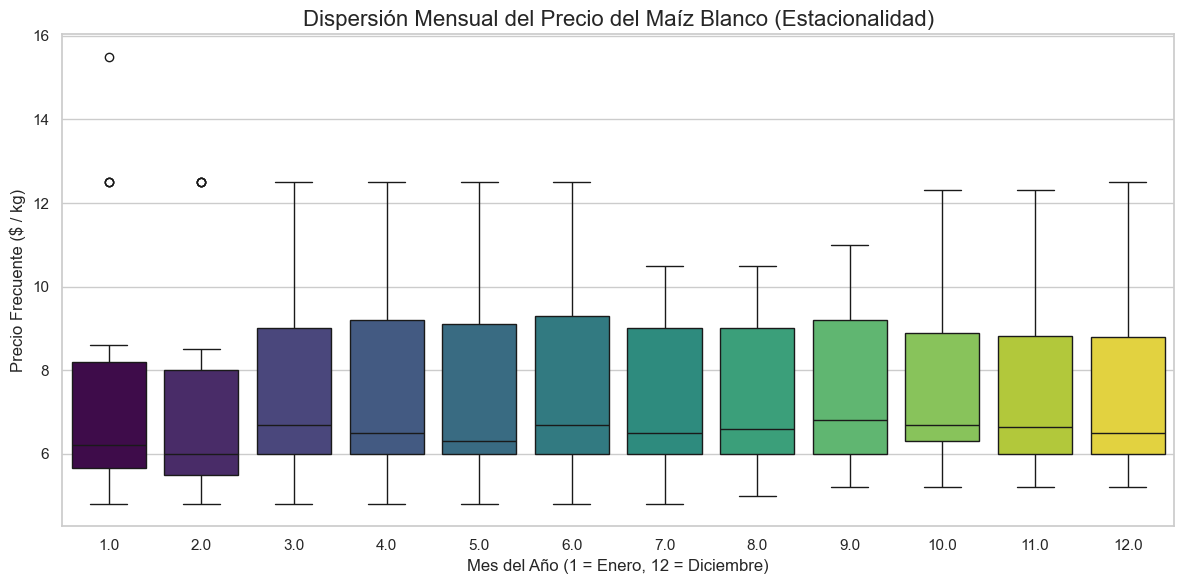

In [4]:
# [CELDA 4: Variabilidad mensual y estacionalidad]

# Vamos a enfocarnos en el Maíz Blanco como ejemplo principal
df_maiz = df_precios[df_precios['Producto_Buscado'] == 'Maíz blanco'].copy()

# Extraemos el mes directamente de la fecha para agrupar
df_maiz['Mes_Numerico'] = df_maiz['Fecha'].dt.month

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_maiz, x='Mes_Numerico', y='Precio Frec', hue='Mes_Numerico', palette='viridis', legend=False)

plt.title('Dispersión Mensual del Precio del Maíz Blanco (Estacionalidad)', fontsize=16)
plt.xlabel('Mes del Año (1 = Enero, 12 = Diciembre)', fontsize=12)
plt.ylabel('Precio Frecuente ($ / kg)', fontsize=12)
plt.tight_layout()
plt.show()

--- RADIOGRAFÍA DE DATOS FALTANTES POR SEMILLA ---


,Producto_Buscado,Semanas_Nulas,Total_Semanas,Porcentaje_Faltante (%)
0,Frijol Negro,396,488,81.15
1,Frijol Pinto,17,524,3.24
2,Haba,17,524,3.24
3,Maíz blanco,17,524,3.24
4,Maíz blanco pozolero,99,517,19.15


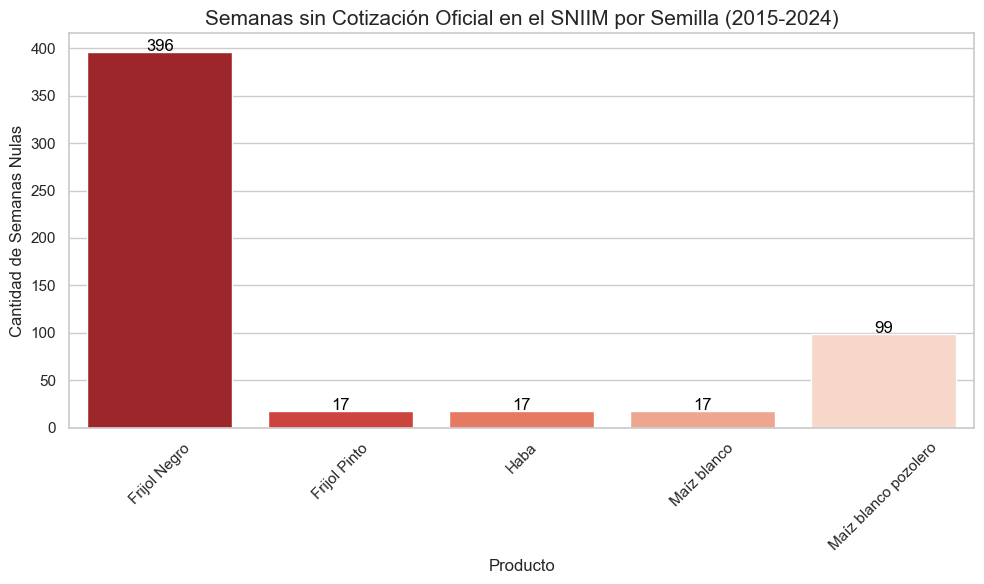

In [5]:
# [CELDA 5: Análisis detallado de valores nulos por semilla]

# 1. Calcular la cantidad de valores nulos (semanas faltantes reales) por cada semilla
nulos_por_semilla = df_precios.groupby('Producto_Buscado')['Precio Frec'].apply(lambda x: x.isnull().sum()).reset_index(name='Semanas_Nulas')

# 2. Calcular el total de semanas procesadas por semilla para sacar el porcentaje
total_semanas = df_precios.groupby('Producto_Buscado').size().reset_index(name='Total_Semanas')

# Unir ambas tablas
resumen_nulos = pd.merge(nulos_por_semilla, total_semanas, on='Producto_Buscado')

# 3. Calcular qué porcentaje de la historia real se perdió
resumen_nulos['Porcentaje_Faltante (%)'] = round((resumen_nulos['Semanas_Nulas'] / resumen_nulos['Total_Semanas']) * 100, 2)

# Mostrar la tabla de diagnóstico
print("--- RADIOGRAFÍA DE DATOS FALTANTES POR SEMILLA ---")
display(resumen_nulos)

# 4. Graficar los resultados para una comparativa visual
plt.figure(figsize=(10, 6))
# Usamos una paleta roja para resaltar que son datos faltantes (alertas)
sns.barplot(data=resumen_nulos, x='Producto_Buscado', y='Semanas_Nulas', hue='Producto_Buscado', palette='Reds_r', legend=False)

plt.title('Semanas sin Cotización Oficial en el SNIIM por Semilla (2015-2024)', fontsize=15)
plt.xlabel('Producto', fontsize=12)
plt.ylabel('Cantidad de Semanas Nulas', fontsize=12)
plt.xticks(rotation=45)

# Añadir el número exacto sobre cada barra
for index, row in resumen_nulos.iterrows():
    plt.text(index, row['Semanas_Nulas'] + 1, f"{int(row['Semanas_Nulas'])}", color='black', ha="center")

plt.tight_layout()
plt.show()

In [6]:
# [CELDA 1: Filtrado y Fusión de Clima y Precios (Corte en Miércoles)]
import pandas as pd
import numpy as np

# 1. CARGAR Y PREPARAR CLIMA
df_clima = pd.read_csv('../Datos climatologicos/Datos_diarios_Juchitepec_01-01-1969_a_31-10-2025.csv')
df_clima = df_clima.replace('NULO', np.nan)

# Forzar columnas a números
for col in ['TMAX', 'TMIN', 'PRECIP']:
    df_clima[col] = pd.to_numeric(df_clima[col], errors='coerce')

df_clima['FECHA'] = pd.to_datetime(df_clima['FECHA'], format='%d/%m/%Y', errors='coerce')

# --- LA SOLUCIÓN: Agrupar el clima en semanas que terminan en MIÉRCOLES ---
# 'W-WED' toma los últimos 7 días y le pone la etiqueta de la fecha del miércoles
df_clima_semanal = df_clima.resample('W-WED', on='FECHA').agg({
    'TMAX': 'mean',
    'TMIN': 'mean',
    'PRECIP': 'sum'
}).reset_index()

# Asegurar que la fecha agrupada no tenga horas/minutos ocultos
df_clima_semanal['FECHA'] = df_clima_semanal['FECHA'].dt.normalize()

# 2. CARGAR Y PREPARAR PRECIOS
df_precios = pd.read_csv('precios_historicos_sniim_continuo.csv')
df_precios['Fecha'] = pd.to_datetime(df_precios['Fecha'], format='%d/%m/%Y', errors='coerce')

# Filtramos las 3 semillas con más datos
semillas_top = ["Frijol Pinto", "Haba", "Maíz blanco"]
df_top = df_precios[df_precios['Producto_Buscado'].isin(semillas_top)].copy()

# --- LA SOLUCIÓN: Forzamos los precios exactamente al MIÉRCOLES de esa semana ---
# Esto garantiza el cruce incluso si por error algún registro cayó en martes o jueves
df_top['Miercoles_Semana'] = df_top['Fecha'].dt.to_period('W-WED').dt.end_time.dt.normalize()

# 3. FUSIÓN ESTRICTA (Coincidencia exacta de Miércoles)
df_modelo = pd.merge(df_top, df_clima_semanal, left_on='Miercoles_Semana', right_on='FECHA', how='inner')

# Limpiamos la columna de clima repetida para que se vea limpio
df_modelo = df_modelo.drop(columns=['FECHA'])

print(f"Fechas alineadas a los Miércoles. Total de registros para modelos: {len(df_modelo)}")
display(df_modelo[['Miercoles_Semana', 'Producto_Buscado', 'Precio Frec', 'TMAX', 'PRECIP']].head())

Fechas alineadas a los Miércoles. Total de registros para modelos: 1521


,Miercoles_Semana,Producto_Buscado,Precio Frec,TMAX,PRECIP
0,2015-01-07,Maíz blanco,4.8,19.857143,8.4
1,2015-01-14,Maíz blanco,4.8,19.714286,0.0
2,2015-01-21,Maíz blanco,4.8,20.000000,6.1
3,2015-01-28,Maíz blanco,4.8,19.714286,12.3
4,2015-02-04,Maíz blanco,4.8,20.142857,3.6


In [7]:
# [CELDA 2: Imputación temporal para el modelo ARIMAX]

# Ordenar cronológicamente para que la interpolación tenga sentido temporal
df_modelo = df_modelo.sort_values(by=['Producto_Buscado', 'Miercoles_Semana'])

columnas_a_interpolar = ['Precio Frec', 'TMAX', 'TMIN', 'PRECIP']

# Aplicamos interpolación lineal por cada semilla
for semilla in semillas_top:
    mascara = df_modelo['Producto_Buscado'] == semilla

    for col in columnas_a_interpolar:
        # Interpolar valores intermedios perdidos
        df_modelo.loc[mascara, col] = df_modelo.loc[mascara, col].interpolate(method='linear')

        # SINTAXIS MODERNA DE PANDAS: bfill() y ffill() directos
        df_modelo.loc[mascara, col] = df_modelo.loc[mascara, col].bfill().ffill()

print("¿Quedan nulos en el dataset?:")
print(df_modelo[['Precio Frec', 'TMAX', 'TMIN', 'PRECIP']].isnull().sum())

¿Quedan nulos en el dataset?:
Precio Frec    0
TMAX           0
TMIN           0
PRECIP         0
dtype: int64


In [8]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:
# [CELDA 3: Entrenamiento ARIMAX por Semilla]
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore") # Ocultamos avisos internos del modelo matemático

variables_exogenas = ['TMAX', 'TMIN', 'PRECIP']
resultados_arima = {}

for semilla in semillas_top:
    print(f"\n{'='*50}")
    print(f"RESULTADOS ARIMAX: {semilla}")
    print(f"{'='*50}")

    # Extraer los datos específicos de esta semilla
    df_semilla = df_modelo[df_modelo['Producto_Buscado'] == semilla].set_index('Miercoles_Semana')

    # 1. Forzar la frecuencia semanal estricta (esto puede crear huecos)
    df_semilla = df_semilla.asfreq('W-WED')

    # 2. LA SOLUCIÓN: Rellenar los huecos que asfreq acaba de crear
    for col in ['Precio Frec'] + variables_exogenas:
        df_semilla[col] = df_semilla[col].interpolate(method='linear').bfill().ffill()

    # Y = Precio a predecir | X = Clima de Juchitepec
    y = df_semilla['Precio Frec']
    X = df_semilla[variables_exogenas]

    try:
        # ARIMA(1, 1, 1) es un modelo base: usa el precio pasado y el error pasado para predecir
        modelo = ARIMA(endog=y, exog=X, order=(1, 1, 1))
        modelo_entrenado = modelo.fit()
        resultados_arima[semilla] = modelo_entrenado

        # Mostramos solo la tabla de coeficientes (donde están las variables climáticas)
        print(modelo_entrenado.summary().tables[1])

    except Exception as e:
        print(f"Error al modelar {semilla}: {e}")

print("\nEntrenamiento completado.")


RESULTADOS ARIMAX: Frijol Pinto
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
TMAX           0.0064      0.020      0.316      0.752      -0.033       0.046
TMIN          -0.0010      0.028     -0.035      0.972      -0.056       0.054
PRECIP        -0.0010      0.002     -0.429      0.668      -0.005       0.004
ar.L1          0.3970     27.092      0.015      0.988     -52.702      53.496
ma.L1         -0.3954     27.128     -0.015      0.988     -53.565      52.774
sigma2         0.3977      0.009     44.331      0.000       0.380       0.415

RESULTADOS ARIMAX: Haba
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
TMAX           0.0328      0.028      1.161      0.246      -0.023       0.088
TMIN          -0.0104      0.038     -0.273      0.785      -0.085       

Con este análisis se descubrió que los valores promediados de clima para el día miércoles, siendo el día con el que se tienen los precios de las 3 semillas con las que más registros se cuentan, no afectan de ninguna manera el precio de las semillas, por lo que el siguiente paso que se propone es desfasar los datos climatológicos hasta que se consiga determinar cuando es que un cambio en el clima afecta los precios. Se planea incluir tambien los datos del monitor de sequía.

In [10]:
import pandas as pd
import os

anios = range(2015, 2025)
cultivos_objetivo = ['Maíz grano', 'Frijol', 'Haba grano']
lista_dfs = []

print("Leyendo archivos históricos (2015-2024)...")

for anio in anios:
    archivo = f'Cierre_agricola_mun_{anio}.csv'

    if os.path.exists(archivo):
        try:
            df_temp = pd.read_csv(archivo, encoding='latin1', low_memory=False)

            # Convertimos a minúsculas y quitamos espacios
            columnas_originales = df_temp.columns
            df_temp.columns = df_temp.columns.str.lower().str.replace(' ', '').str.replace('_', '')

            # --- EL ARREGLO ESTÁ AQUÍ ---
            # Agregamos 'nomcultivosinum' a la lista de disfraces que usa el gobierno
            col_estado = next((col for col in df_temp.columns if col in ['nomestado', 'estado', 'nombreestado']), None)
            col_mun = next((col for col in df_temp.columns if col in ['nommunicipio', 'municipio', 'nombremunicipio']), None)
            col_cultivo = next((col for col in df_temp.columns if col in ['nomcultivo', 'cultivo', 'nombrecultivo', 'nomcultivosinum']), None)
            col_volumen = next((col for col in df_temp.columns if col in ['volumenproduccion', 'volumen', 'produccion', 'volproduccion']), None)

            if not all([col_estado, col_mun, col_cultivo, col_volumen]):
                print(f" [!] {archivo}: Faltan columnas clave. Columnas leídas: {columnas_originales.tolist()[:5]}")
                continue

            # Renombramos a nuestro estándar
            df_temp = df_temp.rename(columns={
                col_estado: 'Estado',
                col_mun: 'Municipio',
                col_cultivo: 'Cultivo',
                col_volumen: 'Produccion'
            })

            # Limpiamos asteriscos y convertimos a número
            df_temp['Produccion'] = pd.to_numeric(
                df_temp['Produccion'].astype(str).str.replace(',', ''), errors='coerce'
            ).fillna(0)

            # Filtramos solo los granos objetivo
            df_temp = df_temp[df_temp['Cultivo'].isin(cultivos_objetivo)]

            lista_dfs.append(df_temp[['Estado', 'Municipio', 'Cultivo', 'Produccion']])
            print(f" [+] {archivo} cargado y homologado exitosamente.")

        except Exception as e:
            print(f" [!] Error al procesar {archivo}: {e}")
    else:
        print(f" [-] Archivo no encontrado: {archivo}")

if lista_dfs:
    print("\nProcesando el acumulado de la década...")
    df_historico = pd.concat(lista_dfs, ignore_index=True)

    # Agrupamos y sumamos
    df_agrupado = df_historico.groupby(
        ['Estado', 'Municipio', 'Cultivo']
    )['Produccion'].sum().reset_index()

    # Extraemos al campeón
    idx_top = df_agrupado.groupby(['Estado', 'Cultivo'])['Produccion'].idxmax()
    df_campeones = df_agrupado.loc[idx_top].reset_index(drop=True)
    df_campeones = df_campeones.sort_values(by=['Cultivo', 'Produccion'], ascending=[True, False])

    print("\n--- TOP MUNICIPIOS PRODUCTORES HISTÓRICOS (ACUMULADO 2015-2024) ---")
    for cultivo in cultivos_objetivo:
        print(f"\n🌾 LOS 3 ESTADOS LÍDERES EN {cultivo.upper()}:")
        top3 = df_campeones[df_campeones['Cultivo'] == cultivo].head(3)
        for index, row in top3.iterrows():
            print(f"  - {row['Estado']} (Mun: {row['Municipio']}): {row['Produccion']:,.2f} Toneladas")

    df_campeones.to_csv('Top_Municipios_Historico.csv', index=False, encoding='utf-8-sig')
    print("\n¡Archivo 'Top_Municipios_Historico.csv' guardado exitosamente!")

Leyendo archivos históricos (2015-2024)...
 [+] Cierre_agricola_mun_2015.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2016.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2017.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2018.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2019.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2020.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2021.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2022.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2023.csv cargado y homologado exitosamente.
 [+] Cierre_agricola_mun_2024.csv cargado y homologado exitosamente.

Procesando el acumulado de la década...

--- TOP MUNICIPIOS PRODUCTORES HISTÓRICOS (ACUMULADO 2015-2024) ---

🌾 LOS 3 ESTADOS LÍDERES EN MAÍZ GRANO:
  - Sinaloa (Mun: Guasave): 12,547,573.48 Toneladas
  - Chihuahua (Mun: Cuauhtémoc): 4,167,071.91 Toneladas
  - Jalis

In [11]:
import pandas as pd
import os

anios = range(2015, 2025)
cultivos_objetivo = ['Maíz grano', 'Frijol', 'Haba grano']
lista_dfs = []

print("Leyendo archivos históricos (2015-2024) para análisis de concentración...")

# 1. Bloque de lectura y limpieza (el mismo que ya blindamos contra errores)
for anio in anios:
    archivo = f'Cierre_agricola_mun_{anio}.csv'
    if os.path.exists(archivo):
        try:
            df_temp = pd.read_csv(archivo, encoding='latin1', low_memory=False)
            df_temp.columns = df_temp.columns.str.lower().str.replace(' ', '').str.replace('_', '')

            col_estado = next((col for col in df_temp.columns if col in ['nomestado', 'estado', 'nombreestado']), None)
            col_mun = next((col for col in df_temp.columns if col in ['nommunicipio', 'municipio', 'nombremunicipio']), None)
            col_cultivo = next((col for col in df_temp.columns if col in ['nomcultivo', 'cultivo', 'nombrecultivo', 'nomcultivosinum']), None)
            col_volumen = next((col for col in df_temp.columns if col in ['volumenproduccion', 'volumen', 'produccion', 'volproduccion']), None)

            if not all([col_estado, col_mun, col_cultivo, col_volumen]):
                continue

            df_temp = df_temp.rename(columns={col_estado: 'Estado', col_mun: 'Municipio', col_cultivo: 'Cultivo', col_volumen: 'Produccion'})
            df_temp['Produccion'] = pd.to_numeric(df_temp['Produccion'].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
            df_temp = df_temp[df_temp['Cultivo'].isin(cultivos_objetivo)]

            lista_dfs.append(df_temp[['Estado', 'Municipio', 'Cultivo', 'Produccion']])
        except Exception as e:
            pass

if lista_dfs:
    print("\nProcesando el acumulado de la década y calculando porcentajes nacionales...\n")
    df_historico = pd.concat(lista_dfs, ignore_index=True)

    # Agrupamos la producción total de la década por municipio
    df_agrupado = df_historico.groupby(['Estado', 'Municipio', 'Cultivo'])['Produccion'].sum().reset_index()

    lista_top50 = []

    print("-" * 60)
    print("MUNICIPIOS QUE CONTROLAN EL 50% DEL MERCADO NACIONAL")
    print("-" * 60)

    # 2. Análisis de concentración por cada cultivo
    for cultivo in cultivos_objetivo:
        # Filtramos solo el cultivo actual
        df_cultivo = df_agrupado[df_agrupado['Cultivo'] == cultivo].copy()

        # Calculamos el total nacional de la década para esta semilla
        total_nacional = df_cultivo['Produccion'].sum()

        # Ordenamos de los más productores a los menos productores
        df_cultivo = df_cultivo.sort_values(by='Produccion', ascending=False)

        # Calculamos la aportación porcentual de cada municipio
        df_cultivo['Porcentaje_Nacional'] = (df_cultivo['Produccion'] / total_nacional) * 100

        # Suma acumulada (Ej: 15% + 12% + 8% ...)
        df_cultivo['Acumulado_Pct'] = df_cultivo['Porcentaje_Nacional'].cumsum()

        # Cortamos exactamente donde se rebasa el 50% del mercado
        # (Usamos shift para asegurarnos de incluir al municipio que nos hace cruzar la meta)
        df_top50_cultivo = df_cultivo[df_cultivo['Acumulado_Pct'].shift(fill_value=0) < 50].copy()

        lista_top50.append(df_top50_cultivo)

        num_municipios = len(df_top50_cultivo)
        total_mun_pais = len(df_cultivo[df_cultivo['Produccion'] > 0])

        print(f"\n{cultivo.upper()}:")
        print(f"   -> Solo {num_municipios} municipios (de {total_mun_pais} productores) generan el 50% del país.")

        # Imprimir los 3 más grandes como ejemplo
        for index, row in df_top50_cultivo.head(3).iterrows():
            print(f"      * {row['Estado']} ({row['Municipio']}): Aporta el {row['Porcentaje_Nacional']:.2f}%")

    # 3. Unimos los resultados y guardamos
    df_final_50pct = pd.concat(lista_top50, ignore_index=True)

    # Redondeamos los porcentajes para que el CSV se vea limpio
    df_final_50pct['Porcentaje_Nacional'] = df_final_50pct['Porcentaje_Nacional'].round(4)
    df_final_50pct['Acumulado_Pct'] = df_final_50pct['Acumulado_Pct'].round(4)

    nombre_archivo = 'Municipios_Top50_Concentracion_Mercado.csv'
    df_final_50pct.to_csv(nombre_archivo, index=False, encoding='utf-8-sig')
    print(f"\nGuardado en: '{nombre_archivo}'")

Leyendo archivos históricos (2015-2024) para análisis de concentración...

Procesando el acumulado de la década y calculando porcentajes nacionales...

------------------------------------------------------------
MUNICIPIOS QUE CONTROLAN EL 50% DEL MERCADO NACIONAL
------------------------------------------------------------

MAÍZ GRANO:
   -> Solo 92 municipios (de 2391 productores) generan el 50% del país.
      * Sinaloa (Guasave): Aporta el 4.67%
      * Sinaloa (Culiacán): Aporta el 3.72%
      * Sinaloa (Ahome): Aporta el 3.62%

FRIJOL:
   -> Solo 23 municipios (de 1889 productores) generan el 50% del país.
      * Zacatecas (Sombrerete): Aporta el 7.27%
      * Zacatecas (Fresnillo): Aporta el 4.78%
      * Sinaloa (Guasave): Aporta el 4.68%

HABA GRANO:
   -> Solo 8 municipios (de 158 productores) generan el 50% del país.
      * Veracruz (Jalacingo): Aporta el 17.61%
      * Veracruz (Perote): Aporta el 7.64%
      * Veracruz (Altotonga): Aporta el 5.48%

Guardado en: 'Municip

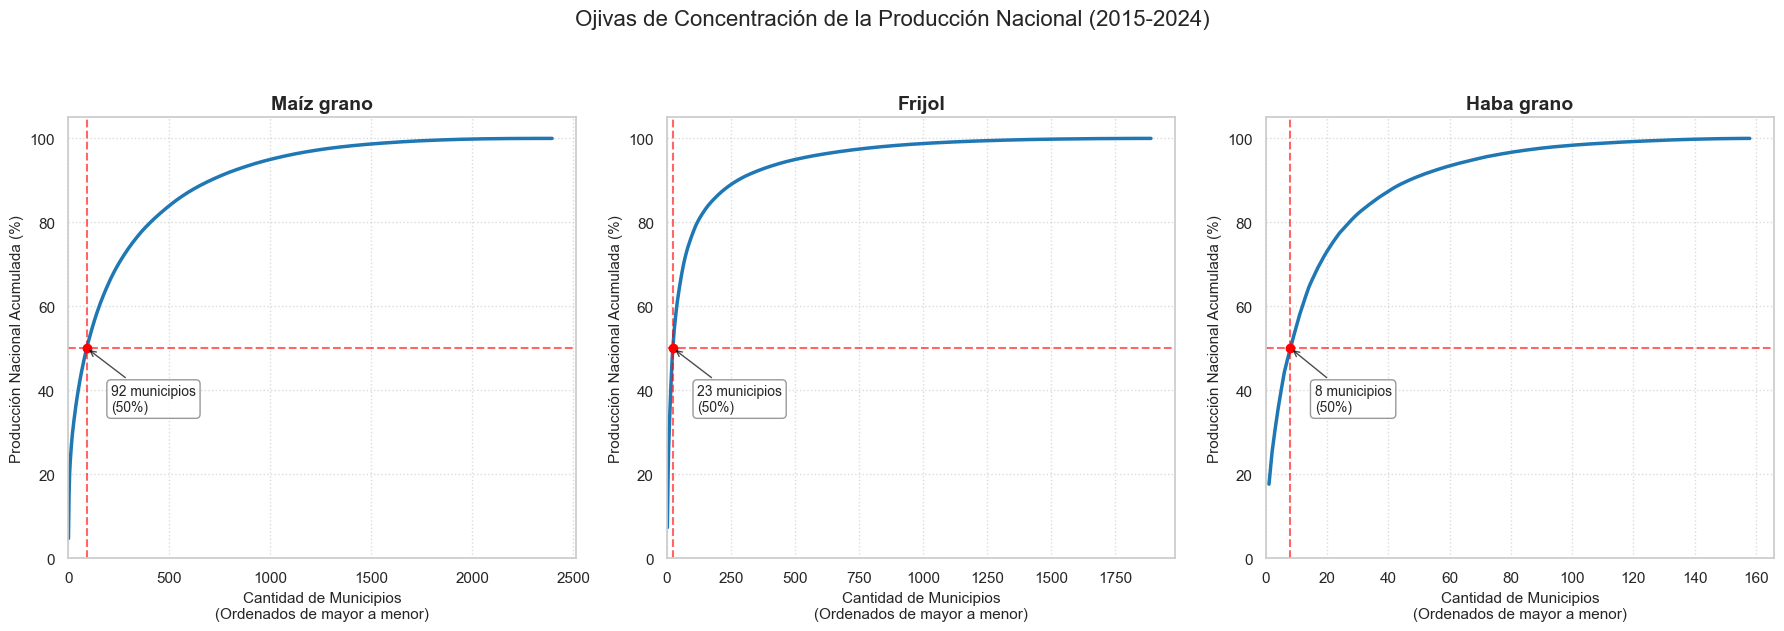

Gráficas generadas exitosamente y guardadas como 'Ojivas_Concentracion_3_Cultivos.png'.


In [21]:
import matplotlib.pyplot as plt

# Configuramos un lienzo amplio con 3 subgráficas (1 fila, 3 columnas)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Ojivas de Concentración de la Producción Nacional (2015-2024)', fontsize=16, y=1.05)

# Iteramos sobre cada cultivo y su respectivo espacio en la gráfica
for i, cultivo in enumerate(cultivos_objetivo):
    ax = axes[i]

    # 1. Preparación de datos (misma lógica matemática que usaste antes)
    df_cultivo = df_agrupado[df_agrupado['Cultivo'] == cultivo].copy()

    # Ordenar de mayor a menor producción
    df_cultivo = df_cultivo.sort_values(by='Produccion', ascending=False).reset_index(drop=True)

    # Calcular porcentajes acumulados de toda la lista (no solo del top 50)
    total_nacional = df_cultivo['Produccion'].sum()
    df_cultivo['Porcentaje_Nacional'] = (df_cultivo['Produccion'] / total_nacional) * 100
    df_cultivo['Acumulado_Pct'] = df_cultivo['Porcentaje_Nacional'].cumsum()

    # El eje X es el conteo de municipios (1, 2, 3...)
    eje_x = range(1, len(df_cultivo) + 1)
    eje_y = df_cultivo['Acumulado_Pct']

    # 2. Trazar la línea principal de la ojiva
    ax.plot(eje_x, eje_y, color='#1f77b4', linewidth=2.5)

    # 3. Encontrar el punto exacto donde se rompe la barrera del 50%
    if not df_cultivo.empty:
        municipios_50pct = df_cultivo[df_cultivo['Acumulado_Pct'] >= 50.0].index[0] + 1

        # Trazar líneas punteadas rojas para marcar el cruce
        ax.axhline(50, color='red', linestyle='--', alpha=0.6)
        ax.axvline(municipios_50pct, color='red', linestyle='--', alpha=0.6)

        # Dibujar un punto en la intersección
        ax.plot(municipios_50pct, 50, marker='o', color='red', markersize=6)

        # Agregar un texto indicando el número de municipios
        desplazamiento_x = len(df_cultivo) * 0.05
        ax.annotate(f'{municipios_50pct} municipios\n(50%)',
                    xy=(municipios_50pct, 50),
                    xytext=(municipios_50pct + desplazamiento_x, 35),
                    arrowprops=dict(arrowstyle="->", color='black', alpha=0.7),
                    fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

    # 4. Formato estético de cada subgráfica
    ax.set_title(cultivo, fontsize=14, fontweight='bold')
    ax.set_xlabel('Cantidad de Municipios\n(Ordenados de mayor a menor)', fontsize=11)
    ax.set_ylabel('Producción Nacional Acumulada (%)', fontsize=11)
    ax.set_ylim(0, 105)
    ax.set_xlim(0, len(df_cultivo) * 1.05) # Dar un pequeño margen a la derecha
    ax.grid(True, linestyle=':', alpha=0.7)

# Ajustar los espacios para que no se encimen los textos
plt.tight_layout()

# Guardar la gráfica en alta calidad (300 DPI es el estándar para documentos formales)
nombre_imagen = 'Ojivas_Concentracion_3_Cultivos.png'
plt.savefig(nombre_imagen, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráficas generadas exitosamente y guardadas como '{nombre_imagen}'.")

Extrayendo historial anual para gráficas de tiempo...


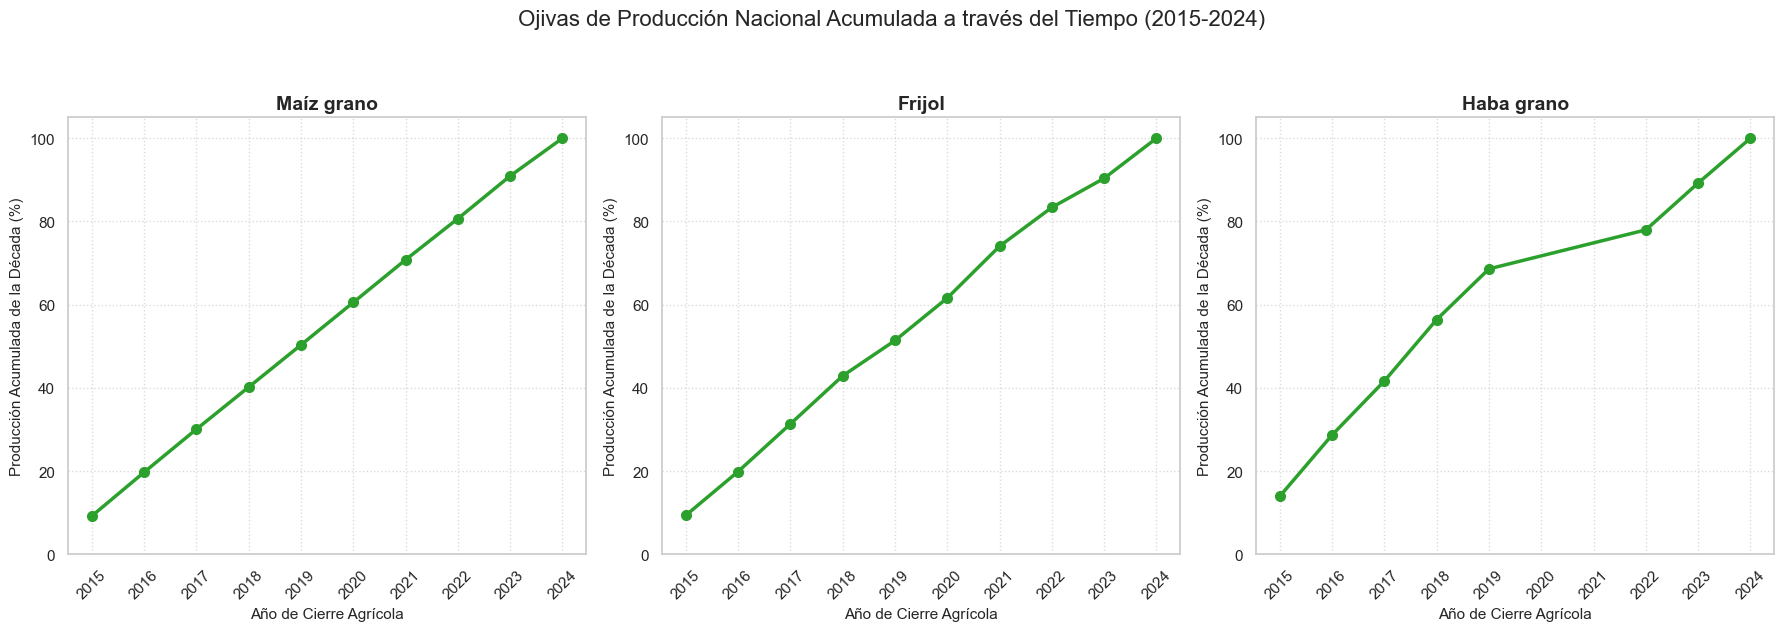

Gráficas temporales generadas y guardadas como 'Ojivas_Tiempo_Produccion.png'.


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import os

anios = range(2015, 2025)
cultivos_objetivo = ['Maíz grano', 'Frijol', 'Haba grano']
lista_temporal = []

print("Extrayendo historial anual para gráficas de tiempo...")

# 1. Lectura rápida (Añadiendo la columna 'Anio')
for anio in anios:
    archivo = f'Cierre_agricola_mun_{anio}.csv'
    if os.path.exists(archivo):
        try:
            df_temp = pd.read_csv(archivo, encoding='latin1', low_memory=False, usecols=lambda x: x.lower().replace(' ', '').replace('_', '') in [
                'nomcultivo', 'cultivo', 'nombrecultivo', 'nomcultivosinum',
                'volumenproduccion', 'volumen', 'produccion', 'volproduccion'
            ])

            df_temp.columns = ['Cultivo', 'Produccion'] # Simplificamos nombres
            df_temp['Produccion'] = pd.to_numeric(df_temp['Produccion'].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
            df_temp = df_temp[df_temp['Cultivo'].isin(cultivos_objetivo)]

            # LA CLAVE: Registramos el año de este archivo
            df_temp['Anio'] = anio

            lista_temporal.append(df_temp)
        except Exception as e:
            pass

if lista_temporal:
    # 2. Agrupación temporal
    df_tiempo = pd.concat(lista_temporal, ignore_index=True)
    df_agrupado_tiempo = df_tiempo.groupby(['Cultivo', 'Anio'])['Produccion'].sum().reset_index()

    # 3. Preparación del lienzo para 3 gráficas
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Ojivas de Producción Nacional Acumulada a través del Tiempo (2015-2024)', fontsize=16, y=1.05)

    for i, cultivo in enumerate(cultivos_objetivo):
        ax = axes[i]

        # Filtramos y ordenamos cronológicamente (de 2015 a 2024)
        df_cultivo = df_agrupado_tiempo[df_agrupado_tiempo['Cultivo'] == cultivo].copy()
        df_cultivo = df_cultivo.sort_values(by='Anio', ascending=True).reset_index(drop=True)

        # Matemáticas de la ojiva temporal
        total_decada = df_cultivo['Produccion'].sum()
        df_cultivo['Porcentaje_Anual'] = (df_cultivo['Produccion'] / total_decada) * 100
        df_cultivo['Acumulado_Pct'] = df_cultivo['Porcentaje_Anual'].cumsum()

        eje_x = df_cultivo['Anio']
        eje_y = df_cultivo['Acumulado_Pct']

        # Trazado de la línea (usamos marcadores para resaltar cada año)
        ax.plot(eje_x, eje_y, marker='o', color='#2ca02c', linewidth=2.5, markersize=7)

        # Formato estético
        ax.set_title(cultivo, fontsize=14, fontweight='bold')
        ax.set_xlabel('Año de Cierre Agrícola', fontsize=11)
        ax.set_ylabel('Producción Acumulada de la Década (%)', fontsize=11)
        ax.set_ylim(0, 105)

        # Asegurar que el eje X muestre los años exactos y no números con decimales
        ax.set_xticks(list(anios))
        ax.tick_params(axis='x', rotation=45) # Rotar años para que no se encimen

        ax.grid(True, linestyle=':', alpha=0.7)

    plt.tight_layout()
    nombre_imagen = 'Ojivas_Tiempo_Produccion.png'
    plt.savefig(nombre_imagen, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Gráficas temporales generadas y guardadas como '{nombre_imagen}'.")
else:
    print("No se pudieron leer los archivos históricos.")

In [12]:
%pip install folium geopy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [13]:
import pandas as pd
import folium
from geopy.geocoders import Nominatim
import time
import os
from IPython.display import clear_output

# 1. Tomamos los datos totales (Asumiendo que 'df_agrupado' existe de tu celda de la década)
df_todos = df_agrupado[df_agrupado['Produccion'] > 0].copy()
df_todos['Busqueda'] = df_todos['Municipio'] + ", " + df_todos['Estado'] + ", México"

archivo_coords = 'Coordenadas_Todos_Municipios.csv'

# 2. Geocodificación Inteligente (Solo busca en internet si no lo ha hecho antes)
if os.path.exists(archivo_coords):
    print("Archivo de coordenadas encontrado. Cargando mapa rápidamente...")
    df_todos_mapa = pd.read_csv(archivo_coords)
else:
    print("Iniciando búsqueda GPS para todo el país (Tomará aprox 30-40 min)...")
    geolocator = Nominatim(user_agent="mapa_nacional_agricola_v1")
    coord_dict = {}
    lugares_unicos = df_todos['Busqueda'].unique()
    total_lugares = len(lugares_unicos)

    for i, lugar in enumerate(lugares_unicos):
        try:
            location = geolocator.geocode(lugar, timeout=10)
            coord_dict[lugar] = (location.latitude, location.longitude) if location else (None, None)
        except Exception:
            coord_dict[lugar] = (None, None)

        time.sleep(1) # Pausa obligatoria
        if (i + 1) % 50 == 0 or (i + 1) == total_lugares:
            clear_output(wait=True)
            print(f"Progreso GPS: {i + 1} / {total_lugares} municipios...")

    df_todos['Latitud'] = df_todos['Busqueda'].map(lambda x: coord_dict.get(x, (None, None))[0])
    df_todos['Longitud'] = df_todos['Busqueda'].map(lambda x: coord_dict.get(x, (None, None))[1])

    df_todos_mapa = df_todos.dropna(subset=['Latitud', 'Longitud']).copy()
    df_todos_mapa.to_csv(archivo_coords, index=False, encoding='utf-8-sig')
    print("Coordenadas guardadas para el futuro.")

# 3. Dibujar el Mapa Maestro
mapa_nacional = folium.Map(location=[23.6345, -102.5528], zoom_start=5, tiles='OpenStreetMap')

colores = {'Maíz grano': '#FFA500', 'Frijol': '#8B4513', 'Haba grano': '#228B22'}

for index, row in df_todos_mapa.iterrows():
    cultivo = row['Cultivo']
    color = colores.get(cultivo, 'blue')

    # Burbujas estandarizadas: Gigantes destacan un poco, pequeños son visibles
    radio = max((row['Produccion'] / 80000), 2.5)

    texto_popup = f"<b>{row['Municipio']}, {row['Estado']}</b><br>Cultivo: {cultivo}<br>Producción Total: {row['Produccion']:,.0f} Ton"

    folium.CircleMarker(
        location=[row['Latitud'], row['Longitud']],
        radius=radio,
        popup=folium.Popup(texto_popup, max_width=250),
        tooltip=f"{row['Municipio']} - {cultivo}",
        color=color, fill=True, fill_color=color, fill_opacity=0.4, weight=0.5
    ).add_to(mapa_nacional)

print("Mapa Nacional Generado (Todos los productores)")
mapa_nacional

Archivo de coordenadas encontrado. Cargando mapa rápidamente...
Mapa Nacional Generado (Todos los productores)


In [14]:
import pandas as pd
import folium

# 1. Cargar el Top 50% y las coordenadas ya buscadas
try:
    df_top50 = pd.read_csv('Municipios_Top50_Concentracion_Mercado.csv')
    df_coords = pd.read_csv('Coordenadas_Todos_Municipios.csv')
except FileNotFoundError:
    print("Asegúrate de haber corrido las celdas anteriores primero.")

# 2. Cruzar para obtener Latitud y Longitud
df_top50['Busqueda'] = df_top50['Municipio'] + ", " + df_top50['Estado'] + ", México"

# Traemos las coordenadas usando un merge simple
df_top50_mapa = pd.merge(
    df_top50,
    df_coords[['Busqueda', 'Cultivo', 'Latitud', 'Longitud']],
    on=['Busqueda', 'Cultivo'],
    how='inner'
)

# 3. Dibujar el Mapa Concentrado
mapa_concentracion = folium.Map(location=[23.6345, -102.5528], zoom_start=5, tiles='OpenStreetMap')

colores = {'Maíz grano': '#FFA500', 'Frijol': '#8B4513', 'Haba grano': '#228B22'}

for index, row in df_top50_mapa.iterrows():
    cultivo = row['Cultivo']
    color = colores.get(cultivo, 'blue')

    # Aquí hacemos las burbujas notoriamente más grandes según su porcentaje
    radio = max(row['Porcentaje_Nacional'] * 1.5, 5)

    texto_popup = f"""
    <div style='width: 200px'>
        <b>{row['Municipio']}, {row['Estado']}</b><br>
        <hr style='margin: 5px 0'>
        <b>Cultivo:</b> {cultivo}<br>
        <b>Aportación Nacional:</b> {row['Porcentaje_Nacional']:.2f}%<br>
        <b>Acumulado (2015-2024):</b> {row['Produccion']:,.0f} Ton
    </div>
    """

    folium.CircleMarker(
        location=[row['Latitud'], row['Longitud']],
        radius=radio,
        popup=folium.Popup(texto_popup, max_width=300),
        tooltip=f"{row['Municipio']} - {row['Porcentaje_Nacional']:.1f}%",
        color=color, fill=True, fill_color=color, fill_opacity=0.7, weight=1
    ).add_to(mapa_concentracion)

print("Mapa de Concentración Generado (Solo el Top 50% del mercado)")
mapa_concentracion

Mapa de Concentración Generado (Solo el Top 50% del mercado)


# Obtención de los datos diarios climatológicos de los municipios de interés.

Primero, obtenemos las coordenadas e ID's de los municipios del archivo KMZ disponible en la página de información estadística climatológica de la CONAGUA, finalmente se guardan estos datos en el CSV 'Catalogo_Estaciones_Clima.csv'.

In [15]:
import zipfile
from bs4 import BeautifulSoup
import pandas as pd
import os

def extraer_estaciones_kmz(ruta_kmz):
    print(f"Abriendo el archivo {ruta_kmz}...")

    with zipfile.ZipFile(ruta_kmz, 'r') as kmz:
        kml_filename = [name for name in kmz.namelist() if name.endswith('.kml')][0]

        with kmz.open(kml_filename, 'r') as kml_file:
            soup = BeautifulSoup(kml_file, 'xml')

    lista_estaciones = []

    print("Extrayendo coordenadas, claves y altitud de las estaciones...")

    for placemark in soup.find_all('Placemark'):
        try:
            nombre = placemark.find('name').text.strip() if placemark.find('name') else 'Desconocida'

            coords_tag = placemark.find('coordinates')
            if coords_tag:
                # Separamos los valores por coma
                valores = coords_tag.text.strip().split(',')

                longitud = float(valores[0])
                latitud = float(valores[1])

                # Buscamos el tercer valor (Altitud). Si el archivo no lo trae, ponemos 0.0
                altitud = float(valores[2]) if len(valores) >= 3 else 0.0

                lista_estaciones.append({
                    'Estacion': nombre,
                    'Latitud': latitud,
                    'Longitud': longitud,
                    'Altitud': altitud
                })
        except Exception as e:
            continue

    df_estaciones = pd.DataFrame(lista_estaciones)
    print(f"¡Éxito! Se extrajeron {len(df_estaciones)} estaciones.")
    return df_estaciones

# --- USO DEL CÓDIGO ---
# Asegúrate de poner el nombre exacto de tu archivo kmz
archivo_mapa = '../Datos climatologicos/EstacionesClimatologicas.kmz'

if os.path.exists(archivo_mapa):
    df_catalogo_estaciones = extraer_estaciones_kmz(archivo_mapa)

    # Imprimimos las primeras filas para revisar si la altitud es real o puros ceros
    display(df_catalogo_estaciones.head(10))

    df_catalogo_estaciones.to_csv('Catalogo_Estaciones_Clima.csv', index=False)
    print("\nCatálogo guardado como 'Catalogo_Estaciones_Clima.csv'")
else:
    print(f"No se encontró el archivo '{archivo_mapa}'.")

Abriendo el archivo ../Datos climatologicos/EstacionesClimatologicas.kmz...
Extrayendo coordenadas, claves y altitud de las estaciones...
¡Éxito! Se extrajeron 5506 estaciones.


,Estacion,Latitud,Longitud,Altitud
0,1001,21.850278,-102.290833,1890.8
1,1004,22.000833,-102.198889,1925.0
2,1005,21.780556,-102.371667,1844.0
3,1008,22.202778,-102.135000,2322.8
4,1010,22.164444,-102.554167,2525.7
5,1011,21.860000,-102.663889,1730.2
6,1012,21.794444,-102.801667,1588.7
7,1013,22.313333,-102.165833,2020.5
8,1014,22.166944,-102.292778,1933.7
9,1015,21.916389,-101.969444,2037.5



Catálogo guardado como 'Catalogo_Estaciones_Clima.csv'


## Scrapper de datos diarios

Se importan librerias y se crea el diccionario con las abreviaciones necesarias para formar las URL's donde estan los datos diarios de cada municipio.

In [16]:
import pandas as pd
import requests
import io
import time

# Diccionario de mapeo: Nombre del estado a abreviatura del SMN
diccionario_smn = {
    'aguascalientes': 'ags', 'baja california': 'bc', 'baja california sur': 'bcs',
    'campeche': 'camp', 'chiapas': 'chis', 'chihuahua': 'chih',
    'coahuila': 'coah', 'colima': 'col', 'ciudad de mexico': 'df',
    'durango': 'dgo', 'guanajuato': 'gto', 'guerrero': 'gro',
    'hidalgo': 'hgo', 'jalisco': 'jal', 'mexico': 'mex',
    'michoacan': 'mich', 'morelos': 'mor', 'nayarit': 'nay',
    'nuevo leon': 'nl', 'oaxaca': 'oax', 'puebla': 'pue',
    'queretaro': 'qro', 'quintana roo': 'qroo',
    'san luis potosi': 'slp', 'sinaloa': 'sin', 'sonora': 'son',
    'tabasco': 'tab', 'tamaulipas': 'tamps', 'tlaxcala': 'tlax',
    'veracruz': 'ver', 'yucatan': 'yuc', 'zacatecas': 'zac'
}

print("Librerías importadas y diccionario de estados configurado.")

Librerías importadas y diccionario de estados configurado.


La función 'obtener_y_procesar_clima', como primer paso se conecta al servidor de CONAGUA variando las abreviaciones de los estados de México e ID's de las estaciones, luego de obtenerlos los filtra en los años de interés (2015 - 2024) y los agrupa semanalmente, tomando como inicio de semana los dias jueves y miercoles como el día final; esto es para coincidir con los datos de precios que el SNIIM dispone en su página.

In [17]:
import pandas as pd
import requests
import io
import urllib3

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

def obtener_y_procesar_clima(id_estacion, nombre_estado):
    estacion_str = str(int(id_estacion)).zfill(5)

    estado_limpio = str(nombre_estado).strip().lower()
    estado_abrev = diccionario_smn.get(estado_limpio)

    if not estado_abrev:
        print(f"Error: No se encontró la abreviatura para el estado '{nombre_estado}'.")
        return None

    url_directa = f"https://smn.conagua.gob.mx/tools/RESOURCES/Normales_Climatologicas/Diarios/{estado_abrev}/dia{estacion_str}.txt"

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:109.0) Gecko/20100101 Firefox/111.0",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
        "Accept-Language": "es-MX,es;q=0.8,en-US;q=0.5,en;q=0.3",
        "Connection": "keep-alive"
    }

    print(f"Descargando datos de la estación {estacion_str} ({estado_abrev.upper()})...")

    try:
        respuesta = requests.get(url_directa, headers=headers, timeout=20, verify=False)
        if respuesta.status_code != 200:
            print(f"  - Fallo en la descarga. Código de servidor: {respuesta.status_code}")
            return None
    except requests.exceptions.RequestException as e:
        print(f"  - Error de conexión: {e}")
        return None

    lineas = respuesta.text.split('\n')

    inicio_tabla = -1
    for i, linea in enumerate(lineas):
        if "FECHA" in linea and "PRECIP" in linea:
            inicio_tabla = i
            break

    if inicio_tabla == -1:
        print("  - Formato de tabla irreconocible.")
        return None

    datos_crudos = '\n'.join(lineas[inicio_tabla:])
    df = pd.read_csv(io.StringIO(datos_crudos), sep=r'\s+', na_values=['NULO', 'Nulo'])

    columnas_necesarias = ['FECHA', 'PRECIP', 'TMAX', 'TMIN']
    if not all(col in df.columns for col in columnas_necesarias):
        print("  - Faltan columnas clave en el archivo.")
        return None

    df = df[columnas_necesarias].copy()

    df['FECHA'] = pd.to_datetime(df['FECHA'], format='%Y-%m-%d', errors='coerce')
    df = df.dropna(subset=['FECHA'])

    # Aplicamos .copy() explícito para desvincularlo del DataFrame original
    df = df[(df['FECHA'] >= '2015-01-01') & (df['FECHA'] <= '2024-12-31')].copy()

    if df.empty:
        print("  - El archivo se leyó bien, pero no hay registros en la década 2015-2024.")
        return None

    # Asignación directa para cambiar el tipo de dato y evitar el TypeError
    df['PRECIP'] = pd.to_numeric(df['PRECIP'], errors='coerce')
    df['TMAX'] = pd.to_numeric(df['TMAX'], errors='coerce')
    df['TMIN'] = pd.to_numeric(df['TMIN'], errors='coerce')

    df_semanal = df.set_index('FECHA').resample('W-WED').agg({
        'PRECIP': 'sum',
        'TMAX': 'mean',
        'TMIN': 'mean'
    }).reset_index()

    df_semanal['TMAX'] = df_semanal['TMAX'].round(2)
    df_semanal['TMIN'] = df_semanal['TMIN'].round(2)
    df_semanal['PRECIP'] = df_semanal['PRECIP'].round(2)

    df_semanal['ID_Estacion'] = id_estacion
    df_semanal['Estado'] = nombre_estado.title()

    print(f"  - Procesamiento completo. {len(df_semanal)} semanas agrupadas.")
    return df_semanal

print("Función cargada en memoria.")

Función cargada en memoria.


En esta celda se ejecuta la función y se prueba con 3 municipios para probar su funcionamiento.

In [18]:
# Lista de prueba. Más adelante la alimentaremos dinámicamente con los municipios del haba.
estaciones_objetivo = [
    {'id': 15039, 'estado': 'mexico'},
    {'id': 22067, 'estado': 'queretaro'},
    {'id': 17046, 'estado': 'morelos'}
]

dataframes_guardados = []

for est in estaciones_objetivo:
    df_resultado = obtener_y_procesar_clima(est['id'], est['estado'])

    if df_resultado is not None:
        dataframes_guardados.append(df_resultado)

    # Pausa de 1 segundo requerida para evitar que el servidor del gobierno nos bloquee
    time.sleep(1)

# Consolidación de datos
if dataframes_guardados:
    df_maestro_clima = pd.concat(dataframes_guardados, ignore_index=True)
    print("\nPrevisualización del Archivo Maestro Consolidado:")
    display(df_maestro_clima.head())
else:
    print("\nNo se pudo generar el archivo maestro porque no se obtuvieron datos válidos.")

Descargando datos de la estación 15039 (MEX)...
  - Procesamiento completo. 522 semanas agrupadas.
Descargando datos de la estación 22067 (QRO)...
  - Procesamiento completo. 522 semanas agrupadas.
Descargando datos de la estación 17046 (MOR)...
  - Procesamiento completo. 522 semanas agrupadas.

Previsualización del Archivo Maestro Consolidado:


,FECHA,PRECIP,TMAX,TMIN,ID_Estacion,Estado
0,2015-01-07,8.4,19.86,6.43,15039,Mexico
1,2015-01-14,0.0,19.71,5.93,15039,Mexico
2,2015-01-21,6.1,20.00,5.64,15039,Mexico
3,2015-01-28,12.3,19.71,5.29,15039,Mexico
4,2015-02-04,3.6,20.14,4.14,15039,Mexico


In [19]:
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree

# 1. Cargar los tres archivos
df_municipios_clave = pd.read_csv('Municipios_Top50_Concentracion_Mercado.csv')
df_coords = pd.read_csv('Coordenadas_Todos_Municipios.csv')
df_catalogo = pd.read_csv('Catalogo_Estaciones_Clima.csv')

# 2. Unir las coordenadas a los municipios de interés
df_muns_con_coords = pd.merge(
    df_municipios_clave,
    df_coords[['Estado', 'Municipio', 'Latitud', 'Longitud']],
    on=['Estado', 'Municipio'],
    how='left'
)

# Revisar si se perdieron municipios en el cruce por diferencias de escritura
nulos = df_muns_con_coords['Latitud'].isnull().sum()
if nulos > 0:
    print(f"Aviso: {nulos} municipios no encontraron coordenadas exactas y se omitirán.")
df_muns_con_coords = df_muns_con_coords.dropna(subset=['Latitud', 'Longitud'])

# 3. Preparar el catálogo de estaciones (extraer ID numérico)
df_catalogo['ID_Num'] = df_catalogo['Estacion'].astype(str).str.extract(r'(\d+)').astype(float)
df_catalogo = df_catalogo.dropna(subset=['ID_Num', 'Latitud', 'Longitud'])

# 4. Cálculo de distancias (Vecino Más Cercano) usando radianes
coords_estaciones = np.radians(df_catalogo[['Latitud', 'Longitud']].values)
coords_municipios = np.radians(df_muns_con_coords[['Latitud', 'Longitud']].values)

arbol = cKDTree(coords_estaciones)
distancias, indices = arbol.query(coords_municipios, k=1)

# 5. Asignar la estación ganadora a cada municipio
df_muns_con_coords['ID_Estacion_Asignada'] = df_catalogo.iloc[indices]['ID_Num'].values

# 6. Crear la lista final eliminando duplicados (por si dos municipios comparten estación)
estaciones_unicas = df_muns_con_coords[['ID_Estacion_Asignada']].drop_duplicates()

estaciones_objetivo = []
for index, row in estaciones_unicas.iterrows():
    estaciones_objetivo.append(int(row['ID_Estacion_Asignada']))

print(f"Filtro espacial completado con éxito.")
print(f"De 5506 estaciones, solo se descargarán {len(estaciones_objetivo)} estaciones únicas.")
display(df_muns_con_coords[['Municipio', 'Estado', 'Cultivo', 'ID_Estacion_Asignada']].head(10))

Filtro espacial completado con éxito.
De 5506 estaciones, solo se descargarán 116 estaciones únicas.


,Municipio,Estado,Cultivo,ID_Estacion_Asignada
0,Guasave,Sinaloa,Maíz grano,25129.0
1,Guasave,Sinaloa,Maíz grano,25129.0
2,Culiacán,Sinaloa,Maíz grano,25016.0
3,Culiacán,Sinaloa,Maíz grano,25016.0
4,Ahome,Sinaloa,Maíz grano,25003.0
5,Ahome,Sinaloa,Maíz grano,25003.0
6,Navolato,Sinaloa,Maíz grano,25171.0
7,Navolato,Sinaloa,Maíz grano,25171.0
8,Sinaloa,Sinaloa,Maíz grano,25015.0
9,Sinaloa,Sinaloa,Maíz grano,25015.0


In [20]:
import pandas as pd
import time

mapa_estados_conagua = {
    '01': 'aguascalientes', '02': 'baja california', '03': 'baja california sur',
    '04': 'campeche', '05': 'coahuila', '06': 'colima', '07': 'chiapas',
    '08': 'chihuahua', '09': 'ciudad de mexico', '10': 'durango',
    '11': 'guanajuato', '12': 'guerrero', '13': 'hidalgo', '14': 'jalisco',
    '15': 'mexico', '16': 'michoacan', '17': 'morelos', '18': 'nayarit',
    '19': 'nuevo leon', '20': 'oaxaca', '21': 'puebla', '22': 'queretaro',
    '23': 'quintana roo', '24': 'san luis potosi', '25': 'sinaloa',
    '26': 'sonora', '27': 'tabasco', '28': 'tamaulipas', '29': 'tlaxcala',
    '30': 'veracruz', '31': 'yucatan', '32': 'zacatecas'
}

dataframes_guardados = []
estaciones_procesadas = 0

# Variables para el diagnóstico de calidad
estaciones_sin_datos = []
estadisticas_faltantes = []
SEMANAS_TOTALES_ESPERADAS = 522

print(f"Iniciando descarga optimizada para {len(estaciones_objetivo)} estaciones...\n")

for id_estacion in estaciones_objetivo:
    id_str = str(id_estacion).zfill(5)
    codigo_estado = id_str[:2]
    nombre_estado = mapa_estados_conagua.get(codigo_estado)

    if nombre_estado:
        df_resultado = obtener_y_procesar_clima(id_estacion, nombre_estado)

        if df_resultado is not None:
            # Calcular calidad de los datos
            semanas_obtenidas = len(df_resultado)
            semanas_faltantes = max(0, SEMANAS_TOTALES_ESPERADAS - semanas_obtenidas)
            porcentaje_faltante = (semanas_faltantes / SEMANAS_TOTALES_ESPERADAS) * 100

            estadisticas_faltantes.append({
                'ID_Estacion': id_estacion,
                'Estado': nombre_estado.title(),
                'Semanas_Obtenidas': semanas_obtenidas,
                'Semanas_Faltantes': semanas_faltantes,
                'Porcentaje_Faltante_Pct': round(porcentaje_faltante, 2)
            })

            dataframes_guardados.append(df_resultado)
        else:
            estaciones_sin_datos.append(id_estacion)

        estaciones_procesadas += 1
        time.sleep(1)
    else:
        print(f"  - Error: Código de estado desconocido para la estación {id_str}")

# --- REPORTE DE CALIDAD ---
print("\n" + "="*50)
print("REPORTE DE DATOS FALTANTES (2015-2024)")
print("="*50)
print(f"Total de estaciones en lista objetivo: {len(estaciones_objetivo)}")
print(f"Estaciones TOTALMENTE VACÍAS (0 datos): {len(estaciones_sin_datos)}")

if estadisticas_faltantes:
    df_stats = pd.DataFrame(estadisticas_faltantes)

    # Clasificación de la calidad de los datos
    completas = len(df_stats[df_stats['Porcentaje_Faltante_Pct'] == 0])
    faltantes_leves = len(df_stats[(df_stats['Porcentaje_Faltante_Pct'] > 0) & (df_stats['Porcentaje_Faltante_Pct'] <= 10)])
    faltantes_graves = len(df_stats[df_stats['Porcentaje_Faltante_Pct'] > 10])

    print("-" * 50)
    print("CLASIFICACIÓN DE ESTACIONES CON DATOS:")
    print(f"1. Semanas completas (0% faltante):         {completas} estaciones")
    print(f"2. Faltantes tolerables (0.1% al 10%):      {faltantes_leves} estaciones")
    print(f"3. Faltantes críticos (Más del 10%):        {faltantes_graves} estaciones")
    print("-" * 50)

    # Guardamos este reporte para su análisis posterior
    df_stats.to_csv('Reporte_Calidad_Clima.csv', index=False)

# --- CONSOLIDACIÓN FINAL ---
if dataframes_guardados:
    df_maestro_clima = pd.concat(dataframes_guardados, ignore_index=True)
    print("\nPrevisualización de los datos climáticos rescatados:")
    display(df_maestro_clima.head())

    nombre_archivo = 'Clima_Municipios_Top50_Semanal.csv'
    df_maestro_clima.to_csv(nombre_archivo, index=False)
    print(f"\nDatos guardados exitosamente como '{nombre_archivo}'.")
else:
    print("\nNo se obtuvieron datos válidos para ninguna estación.")

Iniciando descarga optimizada para 116 estaciones...

Descargando datos de la estación 25129 (SIN)...
  - El archivo se leyó bien, pero no hay registros en la década 2015-2024.
Descargando datos de la estación 25016 (SIN)...
  - El archivo se leyó bien, pero no hay registros en la década 2015-2024.
Descargando datos de la estación 25003 (SIN)...
  - Procesamiento completo. 314 semanas agrupadas.
Descargando datos de la estación 25171 (SIN)...
  - Procesamiento completo. 522 semanas agrupadas.
Descargando datos de la estación 25015 (SIN)...
  - Procesamiento completo. 522 semanas agrupadas.
Descargando datos de la estación 25030 (SIN)...
  - Procesamiento completo. 522 semanas agrupadas.
Descargando datos de la estación 08026 (CHIH)...
  - El archivo se leyó bien, pero no hay registros en la década 2015-2024.
Descargando datos de la estación 08058 (CHIH)...
  - El archivo se leyó bien, pero no hay registros en la década 2015-2024.
Descargando datos de la estación 14355 (JAL)...
  - Proc

,FECHA,PRECIP,TMAX,TMIN,ID_Estacion,Estado
0,2019-01-02,0.0,20.50,7.25,25003,Sinaloa
1,2019-01-09,2.6,23.64,13.07,25003,Sinaloa
2,2019-01-16,6.0,26.64,12.93,25003,Sinaloa
3,2019-01-23,0.0,25.71,13.79,25003,Sinaloa
4,2019-01-30,0.0,26.36,11.50,25003,Sinaloa



Datos guardados exitosamente como 'Clima_Municipios_Top50_Semanal.csv'.
